In [10]:
import os
import pickle as pkl
import pandas as pd

from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats
from pydeseq2.utils import load_example_data

In [11]:
def check_id_duplicate(df, column_name):
    if df[column_name].duplicated().any():
        raise ValueError(f"dataframe: '{df}' , its' column: '{column_name}' has duplicate values")

In [12]:
base_path = "../../../../2nd_6samples_output"
# total_df_original = pd.read_csv(os.path.join(base_path, "total_meet_at_least_one_condition.csv"), sep=",")
df = pd.read_csv(os.path.join(base_path, "dataset2_DSS_then_control_meet_at_least_one_condition_common_sequences.csv"), sep=",")
check_id_duplicate(df, "sequence")


target_cols = ['SRR18078869','SRR18078868','SRR18078867','SRR18078872','SRR18078871','SRR18078870']
df[target_cols] = df[target_cols].replace(1, 0)
total_df = df[~(df[target_cols] == 0).all(axis=1)]
total_df.to_csv(os.path.join(base_path, "dataset2.csv"), sep=",")
# check_id_duplicate(df, "sequence")


# first set the first column as index
total_df.set_index('sequence', inplace=True)
# print(total_df.head())
###add normalization: each value in column/the sum of each column.
columns_normalize = total_df.columns
df_normalized_total = total_df.copy()
df_normalized_total[columns_normalize] = total_df[columns_normalize].div(total_df[columns_normalize].sum())
# print(df_normalized_total[columns_normalize].head())
df_normalized_total[columns_normalize] = df_normalized_total[columns_normalize].mul(10**6).astype(int)

total_df_transposed_normalized = total_df.T
# print(total_df_transposed_normalized.head())

# # print("unnormalized total_df:",total_df)
# total_df_transposed = total_df.T

meta_data = {'condition': ['D', 'D', 'D', 'C', 'C', 'C'], 'group': ['D', 'D', 'D', 'C', 'C', 'C']}
meta_data_total_df = pd.DataFrame(meta_data, index=["SRR18078869", "SRR18078868", "SRR18078867","SRR18078872", "SRR18078871", "SRR18078870"])
print(meta_data_total_df)

            condition group
SRR18078869         D     D
SRR18078868         D     D
SRR18078867         D     D
SRR18078872         C     C
SRR18078871         C     C
SRR18078870         C     C


In [13]:
inference = DefaultInference(n_cpus=1)

dds_total = DeseqDataSet(
    counts=total_df_transposed_normalized,
    metadata=meta_data_total_df,
    design_factors="condition",
    refit_cooks=True,
    inference=inference,
    # n_cpus=8, # n_cpus can be specified here or in the inference object
)
dds_total.deseq2()
stat_res_D_vs_C_total = DeseqStats(dds_total, contrast=["condition", "D", "C"], inference=inference)
stat_res_D_vs_C_total.summary()

/tmp/ipykernel_3840263/67577416.py:3: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds_total = DeseqDataSet(
Fitting size factors...
... done in 0.01 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 48.41 seconds.

Fitting dispersion trend curve...
... done in 1.43 seconds.

Fitting MAP dispersions...
... done in 41.75 seconds.

Fitting LFCs...
... done in 55.44 seconds.

Calculating cook's distance...
... done in 0.04 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 7.77 seconds.



Log2 fold change & Wald test p-value: condition D vs C
                             baseMean  log2FoldChange     lfcSE      stat  \
sequence                                                                    
CCCACCCCCCGTCGCCTCCG        91.985263        9.942670  3.244802  3.064184   
GGAGAAGCCGGCGGGAGCC       7370.281121        9.050701  2.268096  3.990440   
CGGAGAAGCCGGCGGGAGCCCCGG  4704.519484        6.511023  2.233141  2.915635   
TCCCGCCGTCGCCGTCCCCGCT     159.118320        9.211388  3.169303  2.906440   
GCACCCGTAGCTCAGCTGG         42.447593        8.827387  3.722691  2.371238   
...                               ...             ...       ...       ...   
CGAAATAGCTTTAGGGCTA          0.229449       -1.591603  4.367307 -0.364436   
AAGGCGAGCTCAGGGAGGACAG       1.032519       -3.576990  4.249093 -0.841824   
GCCGGCAGGCGCGGGTAAC          1.376691       -3.986293  4.238987 -0.940388   
GTGCATGGCTGTCGTCAGCTCGT      0.229449       -1.591603  4.367307 -0.364436   
CTGAAACTTAAAGGAATTGAC

In [14]:

df_stat_res_D_vs_C_total = stat_res_D_vs_C_total.results_df 
# print(df_stat_res_E_vs_F_total.head())
# df_stat_res_E_vs_F_ecoli = stat_res_E_vs_F_ecoli.results_df 
df_stat_res_D_vs_C_total_sorted = df_stat_res_D_vs_C_total.sort_values(by='padj', ascending=True)
print(df_stat_res_D_vs_C_total_sorted.head())
# print(df_stat_res_E_vs_F_total_sorted.columns)
# check_id_duplicate(df_stat_res_E_vs_F_total_sorted, "sequence")
# df_stat_res_E_vs_F_ecoli_sorted = df_stat_res_E_vs_F_ecoli.sort_values(by='padj', ascending=True)
#print(df_stat_res_E_vs_F_total_sorted.head())
SAVE = True  # whether to save the outputs of this notebook
if SAVE:
    df_stat_res_D_vs_C_total_sorted.to_csv(os.path.join(base_path, "DESeq2_results_D_vs_C_sequence_count_normalize.csv"), index=True)
    # df_stat_res_E_vs_F_total_sorted.to_csv(os.path.join(base_path, "DESeq2_results_E_vs_F_total_sequence_normalize_input_at_least_4_samples.csv"), index=True)
    

                            baseMean  log2FoldChange     lfcSE      stat  \
sequence                                                                   
CGGAGAAGCCGGCGGGAGCC    37378.359048       10.759878  2.119944  5.075548   
TGGTGAACTATGCCTGGGC      4015.667572       11.035042  2.443094  4.516830   
CGAAGCGGGGCTGGGCGCGCGC   2089.926533       10.896141  2.336746  4.662955   
CCGCCGGTGAAATACCACTACT   2213.793579      -14.618987  3.237567 -4.515424   
CGGAGAAGCCGGCGGGAGCCC   24592.358145       10.003553  2.206647  4.533373   

                              pvalue      padj  
sequence                                        
CGGAGAAGCCGGCGGGAGCC    3.863814e-07  0.006293  
TGGTGAACTATGCCTGGGC     6.277224e-06  0.014703  
CGAAGCGGGGCTGGGCGCGCGC  3.117014e-06  0.014703  
CCGCCGGTGAAATACCACTACT  6.319014e-06  0.014703  
CGGAGAAGCCGGCGGGAGCCC   5.804913e-06  0.014703  


                           sequence  log2FoldChange      padj  log10_padj
0              CGGAGAAGCCGGCGGGAGCC       10.759878  0.006293    2.201116
1               TGGTGAACTATGCCTGGGC       11.035042  0.014703    1.832581
2            CGAAGCGGGGCTGGGCGCGCGC       10.896141  0.014703    1.832581
3            CCGCCGGTGAAATACCACTACT      -14.618987  0.014703    1.832581
4             CGGAGAAGCCGGCGGGAGCCC       10.003553  0.014703    1.832581
...                             ...             ...       ...         ...
9704  CGGTGTGGCCGATGACTGGGGTGAAGTCG        5.013596  0.099285    1.003117
9705            AGAAGCCGGCGGGAGCCCC        3.969382  0.099554    1.001939
9706            CAGTTTGGTCCCTATCTGC        4.986934  0.099836    1.000712
9707    GGAGTCGGGTTGCTTGGGAATGCAGCC       -4.692554  0.099982    1.000076
9708         CGCGGCCGCTCCCGGGGAGCCC        4.983359  0.099982    1.000076

[9709 rows x 4 columns]


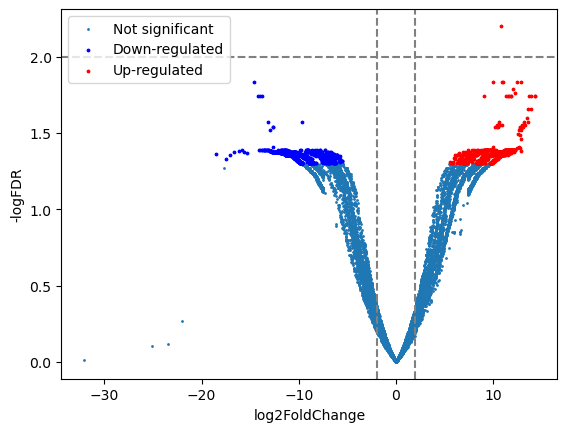

In [15]:
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns
import numpy as np
base_path = "../../../../2nd_6samples_output"
file_path = os.path.join(base_path, "DESeq2_results_D_vs_C_sequence_count_normalize.csv")
df = pd.read_csv(file_path, sep=",", usecols=["sequence","log2FoldChange","padj"])

# --- Step 2: Clean data ---
df = df.copy()
df = df[df['padj'].notnull()]  # Remove rows with NA padj
df['log10_padj'] = -np.log10(df['padj'])
print(df[df['log10_padj'] > 1])


plt.scatter(x=df['log2FoldChange'],y=df['padj'].apply(lambda x:-np.log10(x)),s=1,label="Not significant")

# highlight down- or up- regulated genes
down = df[(df['log2FoldChange']<=-2)&(df['padj']<=0.05)]
up = df[(df['log2FoldChange']>=2)&(df['padj']<=0.05)]

plt.scatter(x=down['log2FoldChange'],y=down['padj'].apply(lambda x:-np.log10(x)),s=3,label="Down-regulated",color="blue")
plt.scatter(x=up['log2FoldChange'],y=up['padj'].apply(lambda x:-np.log10(x)),s=3,label="Up-regulated",color="red")

plt.xlabel("log2FoldChange")
plt.ylabel("-logFDR")
plt.axvline(-2,color="grey",linestyle="--")
plt.axvline(2,color="grey",linestyle="--")
plt.axhline(2,color="grey",linestyle="--")
plt.legend()

                                      sequence  log2FoldChange        pvalue  \
0                         CGGAGAAGCCGGCGGGAGCC       10.759878  3.863814e-07   
1                          TGGTGAACTATGCCTGGGC       11.035042  6.277224e-06   
2                       CGAAGCGGGGCTGGGCGCGCGC       10.896141  3.117014e-06   
3                       CCGCCGGTGAAATACCACTACT      -14.618987  6.319014e-06   
4                        CGGAGAAGCCGGCGGGAGCCC       10.003553  5.804913e-06   
...                                        ...             ...           ...   
73720           CGTTGATTAAGTCCCTGCCCTTTGTACACA       -6.474051  8.287553e-02   
73747                TTCCCTCAGTAACGGCGAGTGAACA       -6.364111  8.828464e-02   
73831  CCGCGGACGCTACGCCGCGACGAGTAGGAGGGCCGCTGC       -6.474051  8.287553e-02   
73867            TCCCGGAGTCGGGTTGCTTGGGAATGCAG       -6.474051  8.287553e-02   
74002        ATAAGCTTGCGTTGATTAAGTCCCTGCCCTTTG       -6.777967  6.818657e-02   

       log10_pvalue  
0          6.4129

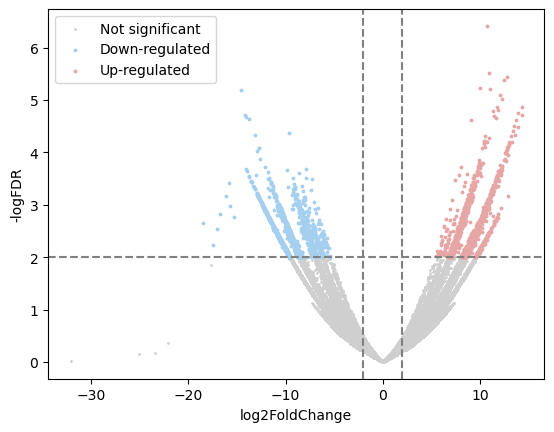

In [16]:
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns
import numpy as np
base_path = "../../../../2nd_6samples_output"
file_path = os.path.join(base_path, "DESeq2_results_D_vs_C_sequence_count_normalize.csv")
df = pd.read_csv(file_path, sep=",", usecols=["sequence","log2FoldChange","pvalue"])

# --- Step 2: Clean data ---
df = df.copy()
# df = df[df['padj'].notnull()]  # Remove rows with NA padj
df['log10_pvalue'] = -np.log10(df['pvalue'])
print(df[df['log10_pvalue'] > 1])


plt.scatter(x=df['log2FoldChange'],y=df['pvalue'].apply(lambda x:-np.log10(x)),s=1,label="Not significant",color="#CFCFCF")

# highlight down- or up- regulated genes
down = df[(df['log2FoldChange']<=-2)&(df['pvalue']<=0.01)]
up = df[(df['log2FoldChange']>=2)&(df['pvalue']<=0.01)]
# plt.scatter(x=down['log2FoldChange'],y=down['pvalue'].apply(lambda x:-np.log10(x)),s=3,label="Down-regulated",color="blue")
# plt.scatter(x=up['log2FoldChange'],y=up['pvalue'].apply(lambda x:-np.log10(x)),s=3,label="Up-regulated",color="red")
# ["#A5CFEF", "#E7A6A6", "#C7AEDB"] 
plt.scatter(x=down['log2FoldChange'],y=down['pvalue'].apply(lambda x:-np.log10(x)),s=3,label="Down-regulated",color="#A5CFEF")
plt.scatter(x=up['log2FoldChange'],y=up['pvalue'].apply(lambda x:-np.log10(x)),s=3,label="Up-regulated",color="#E7A6A6")
plt.xlabel("log2FoldChange")
plt.ylabel("-logFDR")
plt.axvline(-2,color="grey",linestyle="--")
plt.axvline(2,color="grey",linestyle="--")
plt.axhline(2,color="grey",linestyle="--")
plt.legend()

aaa
                           sequence  log2FoldChange      padj  log10_padj
0              CGGAGAAGCCGGCGGGAGCC       10.759878  0.006293    2.201116
1               TGGTGAACTATGCCTGGGC       11.035042  0.014703    1.832581
2            CGAAGCGGGGCTGGGCGCGCGC       10.896141  0.014703    1.832581
3            CCGCCGGTGAAATACCACTACT      -14.618987  0.014703    1.832581
4             CGGAGAAGCCGGCGGGAGCCC       10.003553  0.014703    1.832581
...                             ...             ...       ...         ...
9704  CGGTGTGGCCGATGACTGGGGTGAAGTCG        5.013596  0.099285    1.003117
9705            AGAAGCCGGCGGGAGCCCC        3.969382  0.099554    1.001939
9706            CAGTTTGGTCCCTATCTGC        4.986934  0.099836    1.000712
9707    GGAGTCGGGTTGCTTGGGAATGCAGCC       -4.692554  0.099982    1.000076
9708         CGCGGCCGCTCCCGGGGAGCCC        4.983359  0.099982    1.000076

[9709 rows x 4 columns]


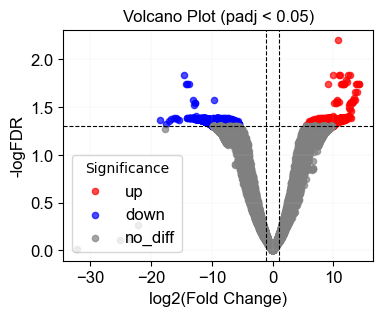

In [17]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm


fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=12)
print("aaa")


base_path = "../../../../2nd_6samples_output"
file_path = os.path.join(base_path, "DESeq2_results_D_vs_C_sequence_count_normalize.csv")
df = pd.read_csv(file_path, sep=",", usecols=["sequence","log2FoldChange","padj"])

df = df.copy()
df = df[df['padj'].notnull()]  # Remove rows with NA padj
#df['padj'] = df['padj'].replace(0, 1e-300)  # Avoid -log10(0) error


df['log10_padj'] = -np.log10(df['padj'])
print(df[df['log10_padj'] > 1])


fc_thresh = 1
pval_thresh = 0.05

conditions = [
    (df['log2FoldChange'] > fc_thresh) & (df['padj'] < pval_thresh),
    (df['log2FoldChange'] < -fc_thresh) & (df['padj'] < pval_thresh),
]
choices = ['up', 'down']
df['significance'] = np.select(conditions, choices, default='no_diff')


plt.figure(figsize=(4, 3))

# Color by significance
colors = {'up': 'red', 'down': 'blue', 'no_diff': 'gray'}
# ["#A5CFEF", "#E7A6A6", "#C7AEDB"] 
for label, color in colors.items():
    subset = df[df['significance'] == label]
    plt.scatter(
        subset['log2FoldChange'],
        subset['log10_padj'],
        c=color, label=label, s=20, alpha=0.7
    )



# top_labels = df[df['significance'] != 'no_diff']
# top_labels = top_labels.sort_values('padj').head(10)  # label top 10 by significance

# for gene_name, row in top_labels.iterrows():
#     plt.text(
#         row['log2FoldChange'],
#         row['log10_padj'] + 0.1,  # offset for clarity
#         gene_name,
#         fontsize=8,
#         ha='center'
#     )


plt.axhline(-np.log10(pval_thresh), color='black', linestyle='--', linewidth=0.8)
plt.axvline(fc_thresh, color='black', linestyle='--', linewidth=0.8)
plt.axvline(-fc_thresh, color='black', linestyle='--', linewidth=0.8)


plt.xlabel('log2(Fold Change)',fontproperties=arial_font)
plt.ylabel("-logFDR",fontproperties=arial_font)
plt.title('Volcano Plot (padj < 0.05)',fontproperties=arial_font)
# Legend with Arial size 12
plt.legend(title='Significance',prop=arial_font)
# Axis tick labels with Arial size 12
plt.xticks(fontproperties=arial_font)
plt.yticks(fontproperties=arial_font)

# plt.grid(True)
plt.grid(True, color="lightgray", linewidth=0.1)

# plt.show()
plt.savefig("figure2_E.pdf", format="pdf", bbox_inches="tight")
